In [14]:
import ot
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import MiniBatchKMeans
import math
import scipy
from scipy.spatial import cKDTree
from scipy import integrate
from scipy import interpolate
from scipy.spatial import Delaunay
from scipy.spatial import Voronoi
from itertools import product
import torch
torch.manual_seed(100000)
import torch.nn as nn
import torch.optim as optim
import pysindy as ps



In [15]:
#settings
N = 5  # Number of variables
F = 8  # Forcing
start = F * np.ones(N)  # Initial state (equilibrium)
start[0] += 0.01  # Add small perturbation to the first variable
dt = 0.01
subset_size = 200#200#50#cell number#TODO: INCREASE
traj_length = int(1e6)#length of trajectory
noise_level = 0#.2#.3
sample_size = int(10000)
slope = 2
simulation_t = int(5e3)
epsilon = 1e-4
#steps = 5#20
def L96(x, t):
    """Lorenz 96 model with constant forcing"""
    return (np.roll(x, -1) - np.roll(x, 2)) * np.roll(x, 1) - x + F 
def L96_vec_unforced(X):

    return (torch.roll(X, shifts=-1, dims=1) - torch.roll(X, shifts=2, dims=1)) * torch.roll(X, shifts=1, dims=1) - X 

t = np.arange(0.0, traj_length*dt, dt)

def invariant_measure(matrix):
    N = len(matrix)
    rhs = (-1) * (epsilon/N) * torch.ones(N)
    rho = torch.linalg.solve(((1 - epsilon) * matrix - torch.eye(N)),rhs)
    return rho

In [16]:
trajectory_clean = scipy.integrate.odeint(L96, start, t)

In [17]:
trajectory = trajectory_clean + np.random.normal(0,noise_level,((traj_length,5)))#loooooooong trajectory
trajectory = trajectory[int(1e3):]

#a random chuck of data
rand_start = np.random.randint(1, len(trajectory)-sample_size)
randpts = torch.tensor(trajectory[rand_start:rand_start+sample_size],dtype = torch.float)
Trandpts = torch.tensor(trajectory[rand_start+1:rand_start+1+sample_size],dtype = torch.float)

#normalization
M_scale = torch.max(torch.abs(randpts))
randpts /= M_scale
Trandpts /= M_scale

#Voronoi cell center
Voronoi_centers = MiniBatchKMeans(n_clusters=subset_size).fit(randpts).cluster_centers_
MEASURE_OT_COST = ot.dist(Voronoi_centers, Voronoi_centers, metric="sqeuclidean")
tree = cKDTree(Voronoi_centers)
Voronoi_centers = torch.tensor(Voronoi_centers,dtype = torch.float)

relu = nn.ReLU()

def decay(x):
    return relu(1-slope*x)
def w(xs):
    dists =  torch.cdist(xs, Voronoi_centers, p =2)
    pre_w = decay(dists)
    return  pre_w / torch.sum(pre_w, dim=1,keepdim = True)


def Ulam(points,Tpoints):
    mat = torch.zeros((subset_size, subset_size))
    #before normalization
    with torch.no_grad():
          randpts_idxs = torch.tensor(tree.query(points.detach().numpy())[1], dtype=torch.int)
    weights = w(Tpoints)
    mat.index_add_(0, randpts_idxs, weights)
    mat = (mat.T)/mat.sum(dim = 1)
    return mat

#column-based OT loss for matrix matching
cell_coords = np.arange(subset_size, dtype=float).reshape(-1, 1)
CELL_OT_COST = ot.dist(cell_coords, cell_coords, metric='sqeuclidean')
class ColumnOTLoss(torch.autograd.Function):
    @staticmethod
    def forward(ctx, U_net):
        predicted = U_net.detach().cpu().numpy()
        gradient = np.empty_like(predicted)
        losses = []
        for source in range(subset_size):
            a = U_true_np[:, source]
            raw_b = predicted[:, source]
            #total = raw_b.sum()
            b = raw_b / raw_b.sum()
            _, log = ot.emd(a / a.sum(), b, CELL_OT_COST, log=True)
            losses.append(log["cost"])
            dual = log["v"]
            # Chain rule through column normalization and averaging.
            gradient[:, source] = (dual - np.dot(dual, b)) / raw_b.sum() / subset_size
        ctx.save_for_backward(torch.as_tensor(gradient, dtype=U_net.dtype, device=U_net.device))
        return U_net.new_tensor(np.mean(losses))

    @staticmethod
    def backward(ctx, grad_output):
        gradient, = ctx.saved_tensors
        return grad_output * gradient
    
#OT loss for measure matching
class W2Loss(torch.autograd.Function):
    @staticmethod
    def forward(ctx, im_net):

        a = np.asarray(im_true_np, dtype=np.float64)
        b = im_net.detach().cpu().numpy().astype(np.float64)
        total_a, total = a.sum(), b.sum()
        a = a / total_a
        b = b / total
        _, log = ot.emd(a, b, MEASURE_OT_COST, log=True)

        # Dual potentials differentiate the cost with respect to normalized b.
        # Apply the chain rule through b = im_net / im_net.sum().
        dual = log["v"]
        gradient = (dual - np.dot(dual, b)) / total
        ctx.save_for_backward(torch.as_tensor(
            gradient, dtype=im_net.dtype, device=im_net.device
        ))
        return im_net.new_tensor(log["cost"])

    @staticmethod
    def backward(ctx, grad_output):
        gradient, = ctx.saved_tensors
        return grad_output * gradient
U_true = Ulam(randpts,Trandpts)
U_true_np = U_true.detach().cpu().numpy()
im_true = invariant_measure(U_true)
im_true_np = im_true.detach().cpu().numpy()

/homes/yinonghyn/.local/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1930: FutureWarning: The default value of `n_init` will change from 3 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=3)


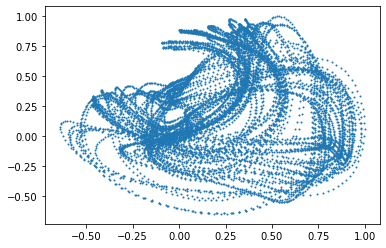

In [18]:
plt.scatter(randpts[:,0],randpts[:,1],s = 1)
#plt.scatter(Voronoi_centers[:,0],Voronoi_centers[:,1])

In [19]:
#torch.manual_seed(100000)
net1 = nn.Sequential(
            nn.Linear(5, 100),
            nn.Tanh(),
            nn.Linear(100, 100),
            nn.Tanh(),
            nn.Linear(100, 100),
            nn.Tanh(),
            nn.Linear(100, 5))

optimizer1 = optim.Adam(net1.parameters(),lr = 1e-3)
# optimizer2 = optim.Adam(net2.parameters(),lr = 1e-3)
# net2.train()
N_iters = 10000

net1.train()
loss1 = []


In [20]:
for i in range(N_iters):
    # Zero gradients for each optimizer
    optimizer1.zero_grad()
 
    net1_randpts = randpts

    V_field = net1(net1_randpts)
    net1_randpts = net1_randpts+dt* V_field
    U_net = Ulam(randpts,net1_randpts)
    L1 = ColumnOTLoss.apply(U_net)
    L1.backward()
    optimizer1.step()
    loss1.append(L1.item())
    if i % 1000 == 0:
        print(f'Iteration {i}, Loss(Ours): {L1.item()}')#, Loss(Pointwise): {L2.item()}')
    # Visualization every 500 iterations

Iteration 0, Loss(Ours): 47.37940979003906
Iteration 1000, Loss(Ours): 0.7012577652931213
Iteration 2000, Loss(Ours): 0.3668321967124939
Iteration 3000, Loss(Ours): 0.3377707898616791
Iteration 4000, Loss(Ours): 0.34462934732437134


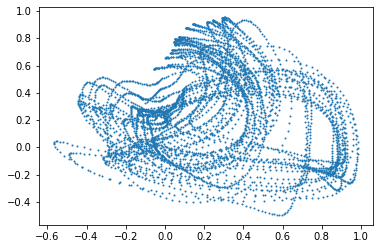

In [21]:
x1 = torch.tensor(randpts[0], dtype=torch.float).reshape(1, 5)
vals1 = [x1.detach().numpy().flatten()]
for _ in range(simulation_t-1):


    V_field = net1(x1)
    x1 = x1 + V_field*dt
    vals1.append(x1.detach().numpy().flatten())
vals1 = np.array(vals1)
plt.scatter(vals1[:, 0], vals1[:, 1], s=1)
plt.show()

Iteration 0, Loss(Ours): 0.014005331322550774


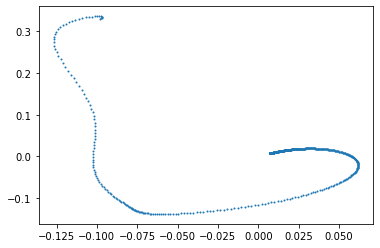

Iteration 1000, Loss(Ours): 0.00023298343876376748
Iteration 2000, Loss(Ours): 0.00021528366778511554


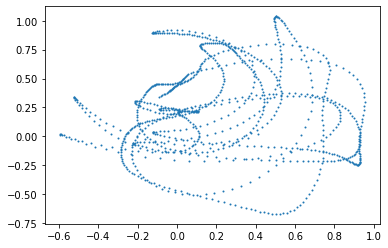

Iteration 3000, Loss(Ours): 0.00018614089640323073
Iteration 4000, Loss(Ours): 0.00019051536219194531


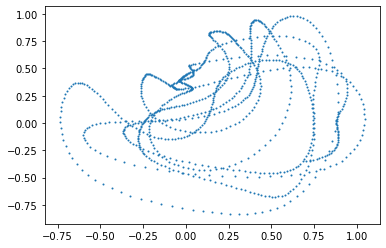

Iteration 5000, Loss(Ours): 0.0001906193938339129
Iteration 6000, Loss(Ours): 0.00018279092910233885


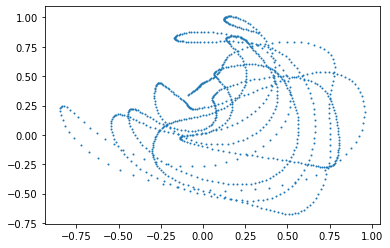

Iteration 7000, Loss(Ours): 0.00018095580162480474
Iteration 8000, Loss(Ours): 0.0001654085936024785


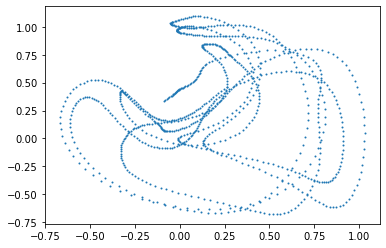

Iteration 9000, Loss(Ours): 0.00014988183102104813


In [33]:
torch.manual_seed(100000)
net2 = nn.Sequential(
            nn.Linear(5, 100),
            nn.Tanh(),
            nn.Linear(100, 100),
            nn.Tanh(),
            nn.Linear(100, 100),
            nn.Tanh(),
            nn.Linear(100, 1))
optimizer2 = optim.Adam(net2.parameters(),lr = 1e-3)
net2.train()
loss2 = []
invert_variables = []
for i in range(N_iters):
    # Zero gradients for each optimizer
    optimizer2.zero_grad()
    net2_randpts = randpts

    V_field2 = L96_vec_unforced(net2_randpts*M_scale)/M_scale
    V_field2 += net2(net2_randpts)
    net2_randpts = net2_randpts+dt* V_field2
    U_net = Ulam(randpts,net2_randpts)
    im_net = invariant_measure(U_net)
    L2 = W2Loss.apply(im_net)
    L2.backward()
    optimizer2.step()
    loss2.append(L2.item())  # Directly use .item() for scalar value

    # Logging
    if i % 1000 == 0:
        print(f'Iteration {i}, Loss(Ours): {L2.item()}')#, Loss(Pointwise): {L2.item()}')
    if i % 2000 == 0:
        x1 = torch.tensor(randpts[0], dtype=torch.float).reshape(1, N)
        # x2 = x1
        vals2= []
        for _ in range(int(1e3)):
            V_field2 = L96_vec_unforced(x1*M_scale)/M_scale
            V_field2 += net2(x1)
            x1 = x1+dt* V_field2
                
            vals2.append(x1.detach().numpy().flatten())
            # x2 = net2(x2)
            # vals2.append(x2.detach().numpy().flatten())
        
        vals2= np.array(vals2)
        plt.scatter(vals2[:, 0], vals2[:, 1], s=1)
        plt.show()

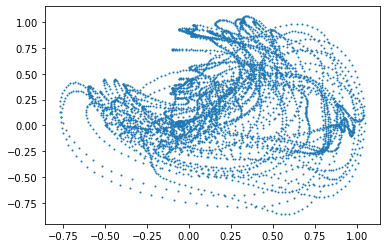

In [34]:

x2 = torch.tensor(randpts[0], dtype=torch.float).reshape(1, 5)
vals2 = [x2.detach().numpy().flatten()]
for _ in range(simulation_t-1):

    V_field2 = L96_vec_unforced(x2*M_scale)/M_scale
    V_field2 += net2(x2)
    x2 = x2+dt* V_field2
                
    vals2.append(x2.detach().numpy().flatten())
        
vals2= np.array(vals2)
plt.scatter(vals2[:, 0], vals2[:, 1], s=1)
plt.show()

In [27]:
GT = scipy.integrate.odeint(L96, M_scale*randpts[0], np.arange(0.0, simulation_t*dt, dt))

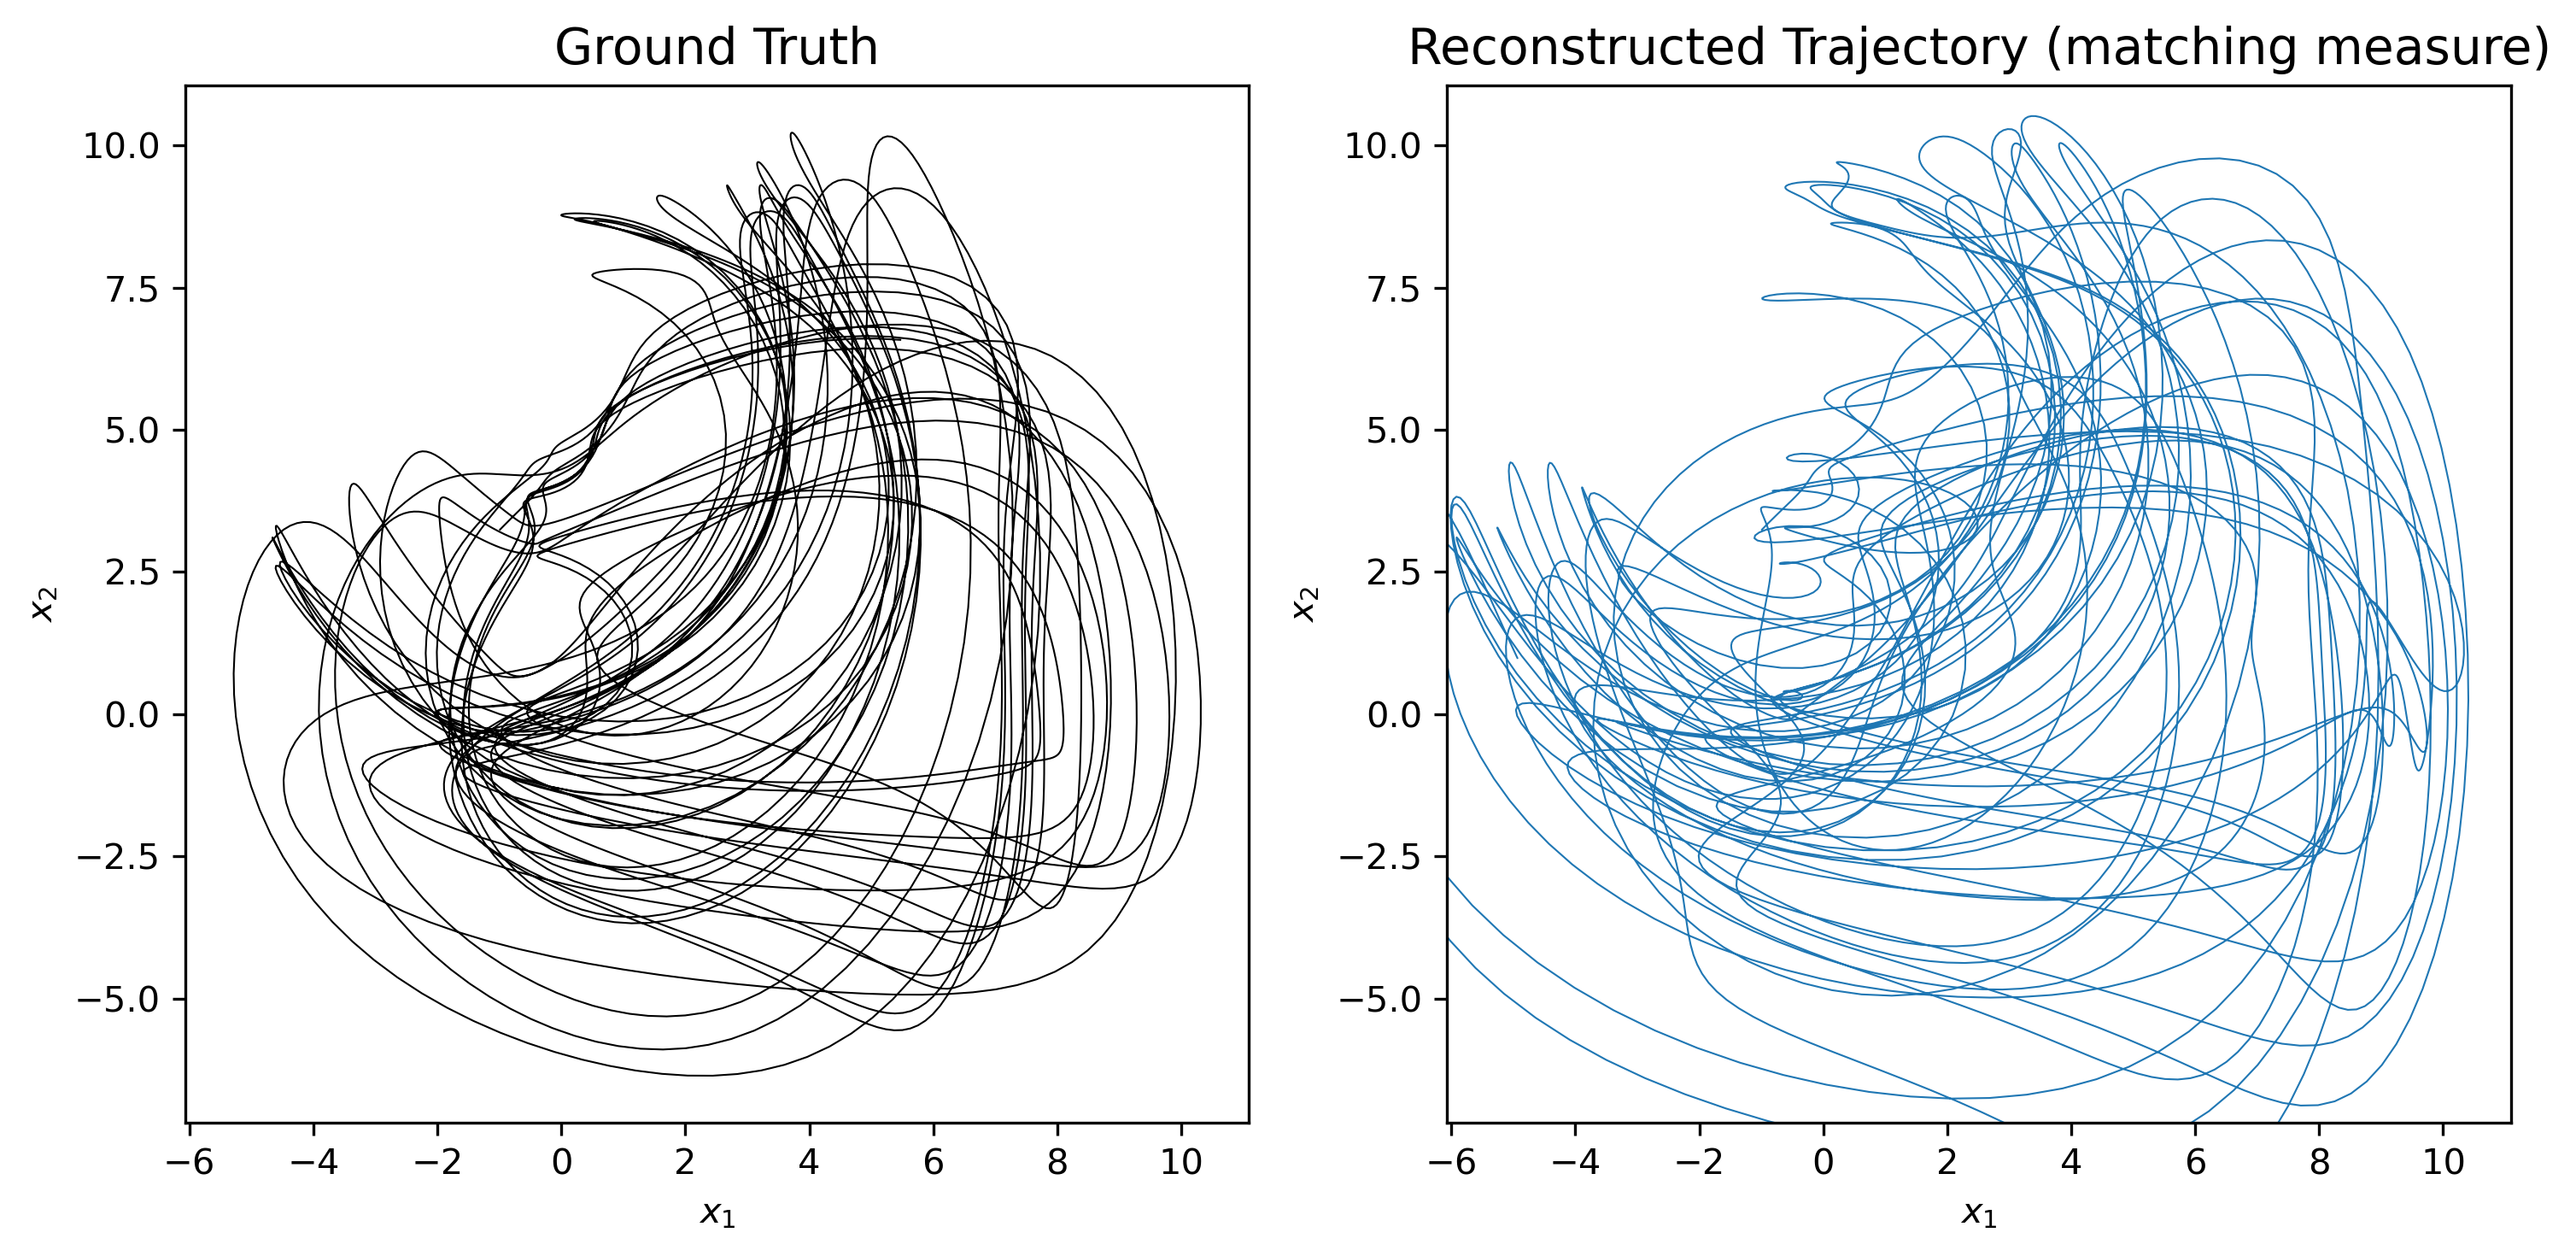

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), dpi=300)

# First plot: Ground Truth
axes[0].plot(GT[:, 0], GT[:, 1], label="Ground Truth", linewidth=0.5, c="black")
axes[0].set_xlabel("$x_{1}$")
axes[0].set_ylabel("$x_{2}$")
axes[0].set_title("Ground Truth",fontsize = 14)

# Store axis limits to keep them consistent
xlims = axes[0].get_xlim()
ylims = axes[0].get_ylim()

# Second plot: Reconstructed Trajectory
axes[1].plot(M_scale * vals2[:, 0], M_scale * vals2[:, 1], linewidth=0.5)
axes[1].set_xlabel("$x_{1}$")
axes[1].set_ylabel("$x_{2}$")
axes[1].set_title("Reconstructed Trajectory (matching measure)",fontsize = 14)
axes[1].set_xlim(xlims)
axes[1].set_ylim(ylims)

plt.tight_layout()
plt.show()

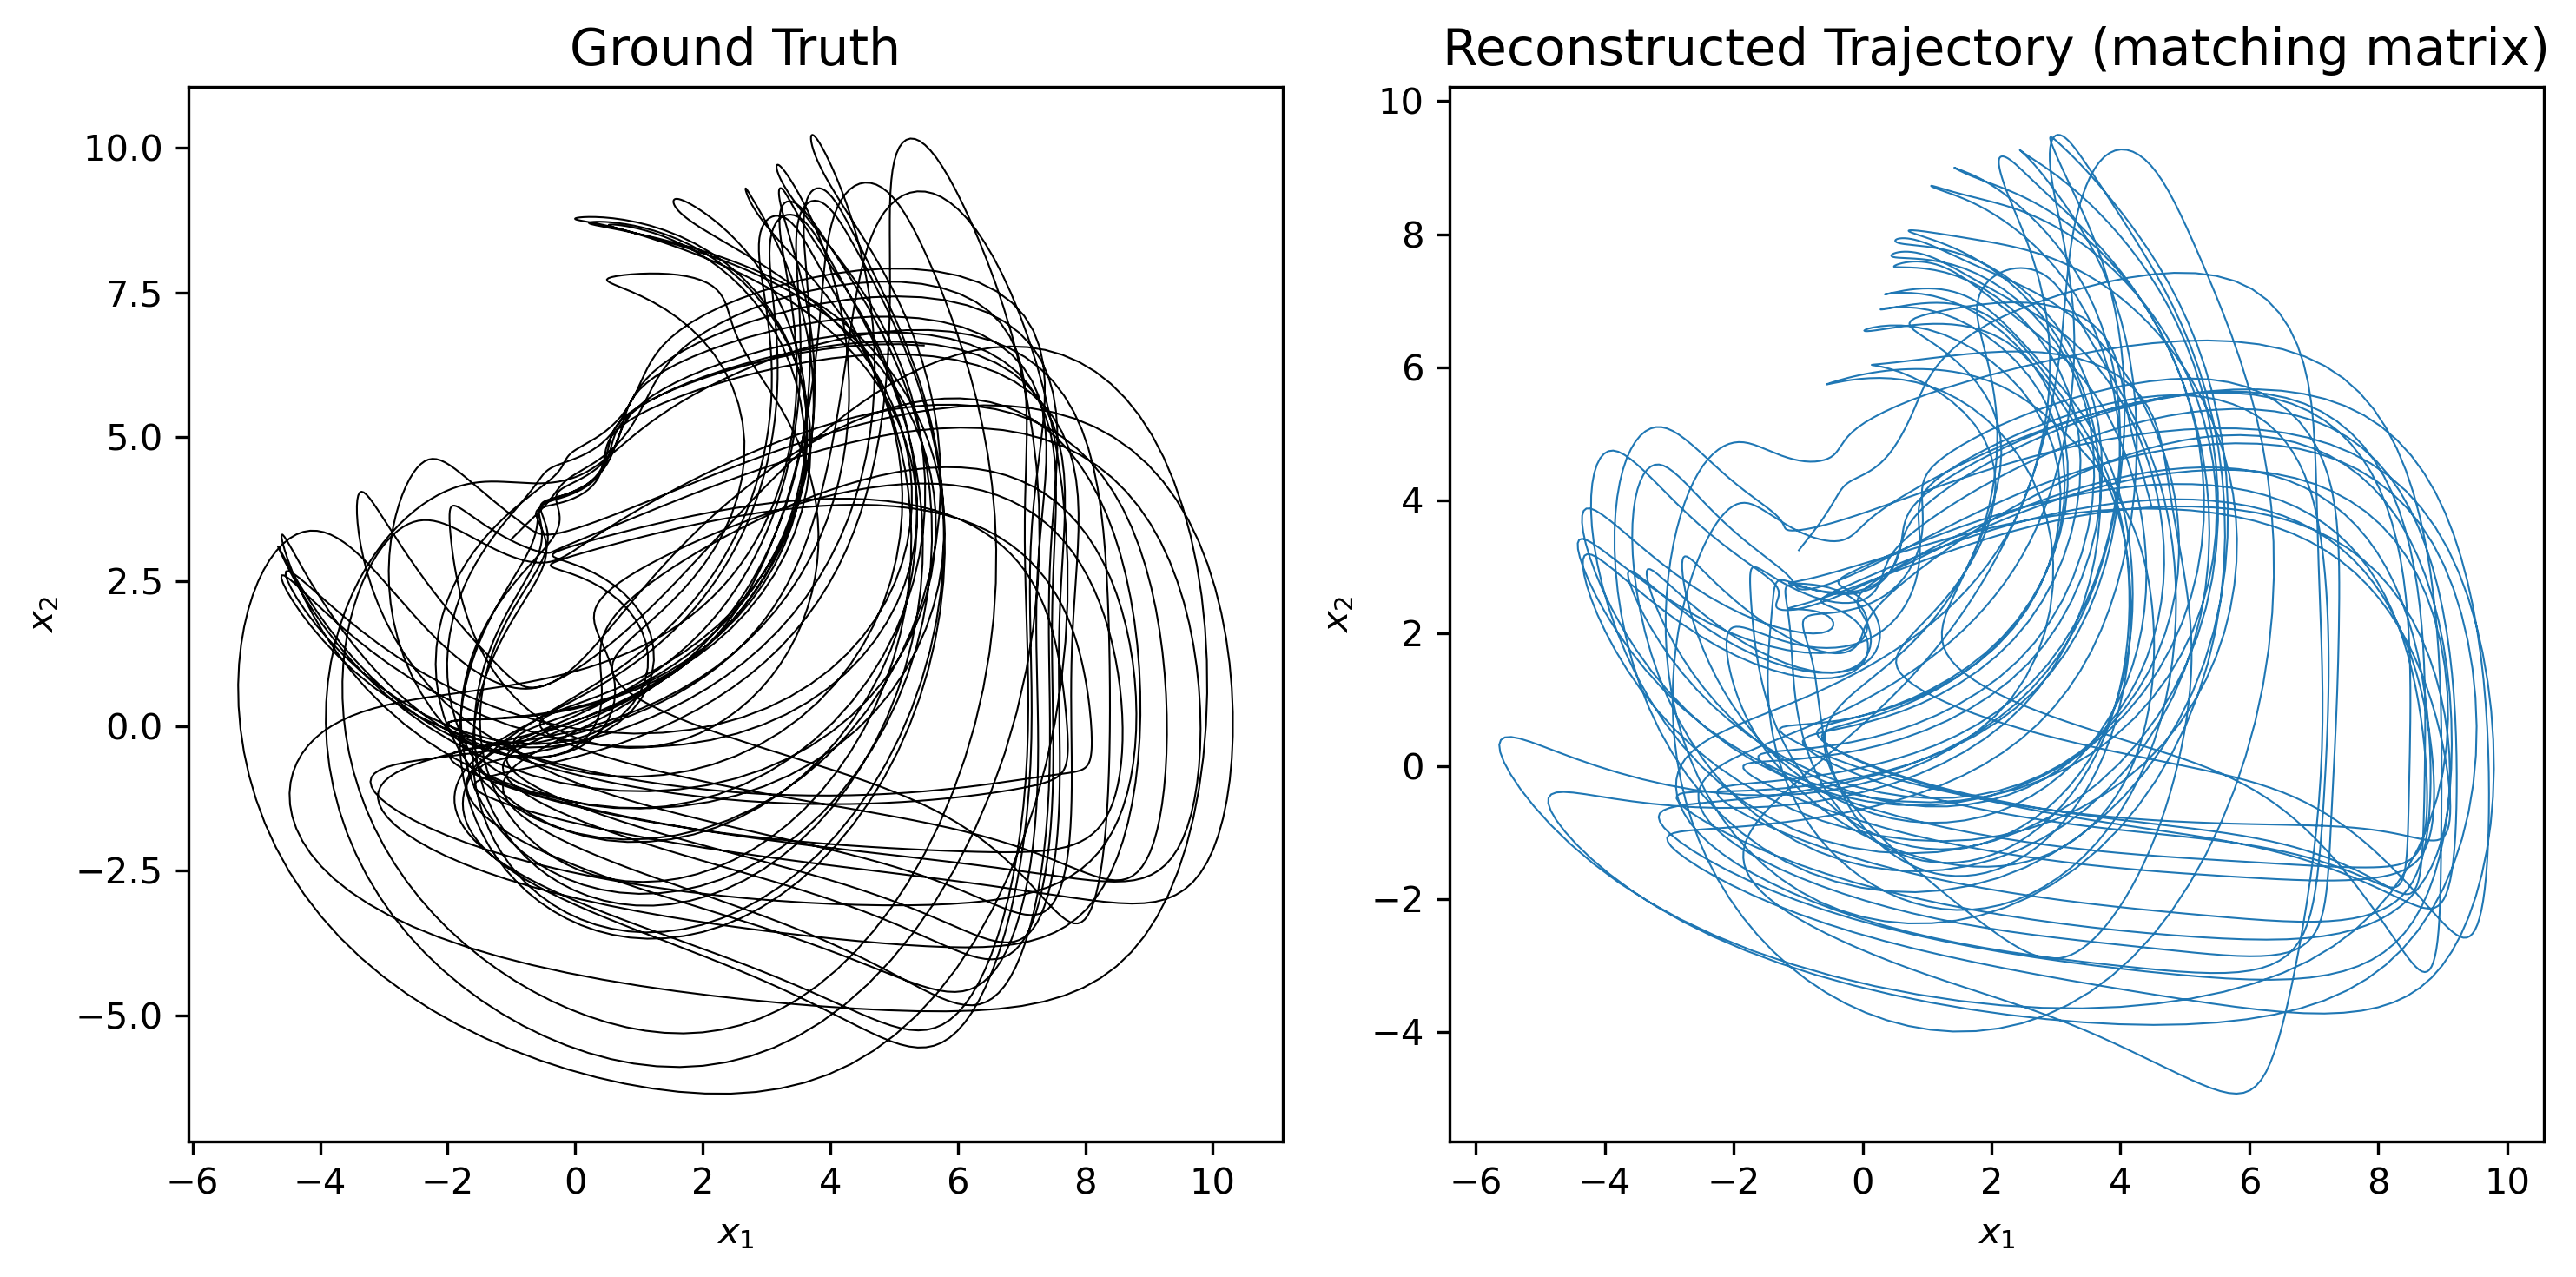

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), dpi=300)

# First plot: Ground Truth
axes[0].plot(GT[:, 0], GT[:, 1], label="Ground Truth", linewidth=0.5, c="black")
axes[0].set_xlabel("$x_{1}$")
axes[0].set_ylabel("$x_{2}$")
axes[0].set_title("Ground Truth",fontsize = 14)

# Store axis limits to keep them consistent
xlims = axes[0].get_xlim()
ylims = axes[0].get_ylim()

# Second plot: Reconstructed Trajectory (matching matrix)
axes[1].plot(M_scale * vals1[:, 0], M_scale * vals1[:, 1], linewidth=0.5)
axes[1].set_xlabel("$x_{1}$")
axes[1].set_ylabel("$x_{2}$")
axes[1].set_title("Reconstructed Trajectory (matching matrix)",fontsize = 14)
# axes[1].set_xlim(xlims)
# axes[1].set_ylim(ylims)

plt.tight_layout()
plt.show()